<a href="https://colab.research.google.com/github/muriloboratto/gnn-neighbor-aggregation/blob/main/gnn_cuda_colab_english.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on: GNN Neighbor Aggregation — CUDA C++ vs. PyTorch

**Objective:** implement and benchmark the aggregation operation $Y=AX$, where $A$ is a sparse adjacency matrix in CSR format, $X$ contains node features, and $Y$ contains aggregated features.

**Environment:** Google Colab → **Runtime → Change runtime type → GPU**. Run the cells in order. This self-contained notebook compiles a CUDA C++ kernel using `nvcc`.

**Three implementations:** PyTorch Sparse CSR, a custom CUDA C++ kernel, and dense PyTorch (small graphs only). The experiment measures **forward aggregation only**, not full GNN training.


## 1. Environment and dependency checks

Google Colab usually provides PyTorch and the CUDA Toolkit. The next cell checks the environment, installs missing Python packages, and reports their versions.


In [1]:
import importlib.util, subprocess, sys, shutil
for package in ("torch", "numpy", "pandas", "matplotlib"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
print("PyTorch:", torch.__version__, "| CUDA PyTorch:", torch.version.cuda)
print("nvcc:", shutil.which("nvcc"))
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Enable a GPU via Runtime > Change runtime type > GPU.")
if not shutil.which("nvcc"):
    raise RuntimeError("nvcc not found. This notebook requires the CUDA Toolkit (for example, a Colab GPU runtime with nvcc).")
subprocess.run(["nvcc", "--version"], check=True)

PyTorch: 2.11.0+cu130 | CUDA PyTorch: 13.0
nvcc: /usr/local/cuda/bin/nvcc
GPU available: True
GPU: Tesla T4


CompletedProcess(args=['nvcc', '--version'], returncode=0)

## 2. CSR representation and neighbor aggregation

For each node $i$ and feature $f$:

$$Y_{i,f}=\sum_{e=\mathrm{row\_ptr}[i]}^{\mathrm{row\_ptr}[i+1]-1}\mathrm{values}[e]\,X_{\mathrm{col\_idx}[e],f}.$$

In this benchmark, each node has `degree` neighbor entries sampled **with replacement**. Every entry has weight $1/degree$, so the output is the **average of sampled neighbors**. Duplicate edges are allowed and are accumulated consistently by both implementations.


In [2]:
# CPU demonstration to inspect CSR arrays.
row_demo = torch.tensor([0, 2, 3, 5], dtype=torch.int32)
col_demo = torch.tensor([1, 2, 0, 0, 1], dtype=torch.int32)
val_demo = torch.tensor([0.5, 0.5, 1.0, 0.5, 0.5], dtype=torch.float32)
x_demo = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])
a_demo = torch.sparse_csr_tensor(row_demo, col_demo, val_demo, size=(3, 3))
print("Dense adjacency (for visualization only):\n", a_demo.to_dense())
print("Node features X:\n", x_demo)
print("Aggregation Y=A@X:\n", torch.sparse.mm(a_demo, x_demo))

Dense adjacency (for visualization only):
 tensor([[0.0000, 0.5000, 0.5000],
        [1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000]])
Node features X:
 tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])
Aggregation Y=A@X:
 tensor([[4., 5.],
        [1., 2.],
        [2., 3.]])


/tmp/ipykernel_1524/846367898.py:6: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  a_demo = torch.sparse_csr_tensor(row_demo, col_demo, val_demo, size=(3, 3))
/tmp/ipykernel_1524/846367898.py:6: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  a_demo = torch.sparse_csr_tensor(row_demo, col_demo, val_demo, size=(3, 3))


## 3. CUDA C++ kernel

**Thread mapping:** each CUDA thread computes one `(node, feature)` output element. It traverses that node's neighbor list sequentially. This is an **educational baseline**, without warp-per-node scheduling or cooperative reductions.


In [3]:
from pathlib import Path
cuda_source = r'''#include <cuda_runtime.h>
#include <cstdio>

// One CUDA thread computes one (vertex, feature) output element.
__global__ void aggregate_csr_kernel(const int* __restrict__ row_ptr,
                                     const int* __restrict__ col_idx,
                                     const float* __restrict__ values,
                                     const float* __restrict__ x,
                                     float* __restrict__ y,
                                     int n, int features) {
    int tid = blockIdx.x * blockDim.x + threadIdx.x;
    int total = n * features;
    if (tid >= total) return;
    int row = tid / features;
    int feature = tid % features;
    float sum = 0.0f;
    for (int e = row_ptr[row]; e < row_ptr[row + 1]; ++e) {
        sum += values[e] * x[col_idx[e] * features + feature];
    }
    y[tid] = sum;
}

extern "C" int aggregate_csr(const int* row_ptr, const int* col_idx,
                              const float* values, const float* x, float* y,
                              int n, int features, void* stream_ptr) {
    if (n <= 0 || features <= 0) return -1;
    const int threads = 256;
    long long total = (long long)n * features;
    if (total > 2147483647LL) return -2;
    cudaStream_t stream = reinterpret_cast<cudaStream_t>(stream_ptr);
    aggregate_csr_kernel<<<(total + threads - 1) / threads, threads, 0, stream>>>(
        row_ptr, col_idx, values, x, y, n, features);
    return (int)cudaGetLastError();
}
'''
Path("neighbor_aggregate.cu").write_text(cuda_source)
print(cuda_source)

#include <cuda_runtime.h>
#include <cstdio>

// One CUDA thread computes one (vertex, feature) output element.
__global__ void aggregate_csr_kernel(const int* __restrict__ row_ptr,
                                     const int* __restrict__ col_idx,
                                     const float* __restrict__ values,
                                     const float* __restrict__ x,
                                     float* __restrict__ y,
                                     int n, int features) {
    int tid = blockIdx.x * blockDim.x + threadIdx.x;
    int total = n * features;
    if (tid >= total) return;
    int row = tid / features;
    int feature = tid % features;
    float sum = 0.0f;
    for (int e = row_ptr[row]; e < row_ptr[row + 1]; ++e) {
        sum += values[e] * x[col_idx[e] * features + feature];
    }
    y[tid] = sum;
}

extern "C" int aggregate_csr(const int* row_ptr, const int* col_idx,
                              const float* values, const float* x, float* 

## 4. Compile the CUDA kernel

We compile a shared library (`.so`) and invoke it using `ctypes` with PyTorch CUDA tensor pointers. This avoids unnecessary CPU↔GPU copies: we pass device pointers and the **current CUDA stream**.


In [4]:
import ctypes
cmd = ["nvcc", "-O3", "-std=c++17", "-shared", "-Xcompiler", "-fPIC",
       "neighbor_aggregate.cu", "-o", "libneighbor_aggregate.so"]
subprocess.run(cmd, check=True)
lib = ctypes.CDLL(str(Path("libneighbor_aggregate.so").resolve()))
lib.aggregate_csr.argtypes = [ctypes.c_void_p] * 5 + [ctypes.c_int, ctypes.c_int, ctypes.c_void_p]
lib.aggregate_csr.restype = ctypes.c_int
print("CUDA kernel compiled successfully.")

CUDA kernel compiled successfully.


## 5. Input data and equivalent implementations

Every implementation uses the **same** `row_ptr`, `col_idx`, `values`, and `X`. We generate reproducible inputs on the CPU and transfer them to the GPU **before timing**.


In [5]:
def make_graph(n, degree, features, seed=42):
    g = torch.Generator(device="cpu").manual_seed(seed)
    row = torch.arange(0, (n + 1) * degree, degree, dtype=torch.int32)
    col = torch.randint(n, (n * degree,), generator=g, dtype=torch.int32)
    val = torch.full((n * degree,), 1.0 / degree, dtype=torch.float32)
    x = torch.randn((n, features), generator=g, dtype=torch.float32)
    return row.cuda(), col.cuda(), val.cuda(), x.cuda()

def make_custom(row, col, val, x):
    n, features = x.shape
    out = torch.empty_like(x)
    def run():
        stream = torch.cuda.current_stream().cuda_stream
        err = lib.aggregate_csr(row.data_ptr(), col.data_ptr(), val.data_ptr(),
                                x.data_ptr(), out.data_ptr(), n, features, stream)
        if err:
            raise RuntimeError(f"CUDA kernel launch failed, error code {err}")
        return out
    return run

def gpu_time_ms(fn, warmup=20, repeats=100):
    for _ in range(warmup): fn()
    torch.cuda.synchronize()
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)
    start.record()
    for _ in range(repeats): fn()
    end.record()
    end.synchronize()
    return start.elapsed_time(end) / repeats


## 6. Correctness check and initial benchmark

We use `float32` tolerances because floating-point reduction order can differ. **Speedup = PyTorch time / custom CUDA time**; a value greater than 1 indicates that the custom kernel is faster.


In [6]:
N, DEGREE, FEATURES, REPEATS = 2048, 16, 64, 100
row, col, val, x = make_graph(N, DEGREE, FEATURES)
csr = torch.sparse_csr_tensor(row, col, val, size=(N, N), device="cuda")
custom_fn = make_custom(row, col, val, x)
sparse_fn = lambda: torch.sparse.mm(csr, x)
reference = sparse_fn()
custom_output = custom_fn()
torch.cuda.synchronize()
torch.testing.assert_close(custom_output, reference, rtol=1e-4, atol=1e-4)
print("Correctness: PASS")
t_pytorch = gpu_time_ms(sparse_fn, repeats=REPEATS)
t_cuda = gpu_time_ms(custom_fn, repeats=REPEATS)
print(f"PyTorch CSR: {t_pytorch:.5f} ms")
print(f"CUDA custom: {t_cuda:.5f} ms")
print(f"Speedup PyTorch/CUDA: {t_pytorch/t_cuda:.2f}x")

Correctness: PASS
PyTorch CSR: 0.04671 ms
CUDA custom: 0.02322 ms
Speedup PyTorch/CUDA: 2.01x


## 7. Benchmark across graph sizes

Dense PyTorch is limited to `N <= 2048` to avoid excessive quadratic memory allocation. Measurements include GPU kernel launches and execution, but **exclude** data generation, compilation, and CPU↔GPU transfers. Repeated measurements amortize some instrumentation overhead.


In [7]:
SIZES = [512, 1024, 2048, 4096, 8192]
DEGREE, FEATURES, REPEATS = 16, 64, 100
results = []
for n in SIZES:
    row, col, val, x = make_graph(n, DEGREE, FEATURES)
    csr = torch.sparse_csr_tensor(row, col, val, size=(n, n), device="cuda")
    custom_fn = make_custom(row, col, val, x)
    sparse_fn = lambda csr=csr, x=x: torch.sparse.mm(csr, x)
    reference = sparse_fn()
    torch.testing.assert_close(custom_fn(), reference, rtol=1e-4, atol=1e-4)
    sparse_ms = gpu_time_ms(sparse_fn, repeats=REPEATS)
    custom_ms = gpu_time_ms(custom_fn, repeats=REPEATS)
    dense_ms = float("nan")
    if n <= 2048:
        dense = csr.to_dense()
        dense_fn = lambda dense=dense, x=x: dense @ x
        torch.testing.assert_close(dense_fn(), reference, rtol=1e-4, atol=1e-4)
        dense_ms = gpu_time_ms(dense_fn, repeats=REPEATS)
    results.append({"Nodes": n, "Degree": DEGREE, "Features": FEATURES,
                    "PyTorch CSR (ms)": sparse_ms, "CUDA custom (ms)": custom_ms,
                    "PyTorch Dense (ms)": dense_ms, "Speedup CSR/CUDA": sparse_ms / custom_ms})
df = pd.DataFrame(results)
display(df.round(5))

,Nodes,Degree,Features,PyTorch CSR (ms),CUDA custom (ms),PyTorch Dense (ms),Speedup CSR/CUDA
0,512,16,64,0.03414,0.01566,0.03557,2.17959
1,1024,16,64,0.03350,0.01652,0.08985,2.02797
2,2048,16,64,0.05204,0.02681,0.24193,1.94097
3,4096,16,64,0.07492,0.04863,NaN,1.54039
4,8192,16,64,0.13468,0.09970,NaN,1.35082


## 8. Plotting and exporting results


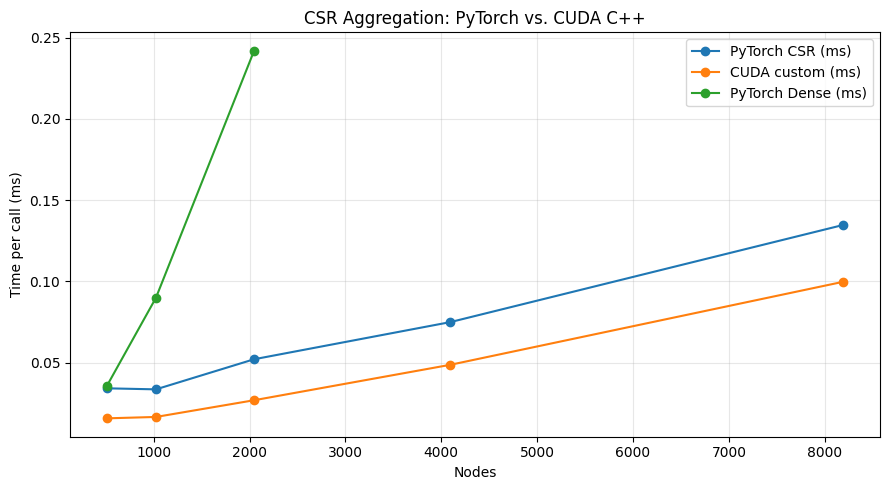

Results saved to gnn_cuda_results.csv


In [8]:
ax = df.plot(x="Nodes", y=["PyTorch CSR (ms)", "CUDA custom (ms)", "PyTorch Dense (ms)"],
             marker="o", figsize=(9, 5))
ax.set_ylabel("Time per call (ms)")
ax.set_title("CSR Aggregation: PyTorch vs. CUDA C++")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
df.to_csv("gnn_cuda_results.csv", index=False)
print("Results saved to gnn_cuda_results.csv")
# Optional in Google Colab: uncomment to download the CSV
# from google.colab import files
# files.download("gnn_cuda_results.csv")